In [1]:
# Import libraries
import xml.etree.ElementTree as ET

import re
import json

from bs4 import BeautifulSoup

import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

import ahocorasick

from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
import pandas as pd

from itertools import combinations
import math


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\edgar\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\edgar\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\edgar\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\edgar\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [2]:
# Define the path to the XML file
file_path = "data/Posts.xml"

# Define a function to parse the XML and extract relevant fields
def parse_posts(file_path):
    posts_data = []

    # Parse the XML file
    tree = ET.parse(file_path)
    root = tree.getroot()

    # Iterate through each row in the XML file
    for row in root.findall("row"):
        post = {
            "Id": row.attrib.get("Id"),
            "PostTypeId": row.attrib.get("PostTypeId"),
            "ParentId": row.attrib.get("ParentId"),
            "AcceptedAnswerId": row.attrib.get("AcceptedAnswerId"),
            "Score": row.attrib.get("Score"),
            "ViewCount": row.attrib.get("ViewCount"),
            "Tags": row.attrib.get("Tags"),
            "Title": row.attrib.get("Title"),
            "CreationDate": row.attrib.get("CreationDate"),
            # "OwnerUserId": row.attrib.get("OwnerUserId"),
            "AnswerCount": row.attrib.get("AnswerCount"),
            "Body": row.attrib.get("Body"),  # For content analysis
        }
        posts_data.append(post)

    return posts_data

# Call the function to parse the XML file
posts_data = parse_posts(file_path)

# Example output: First 5 posts
for post in posts_data[:5]:
    print(post)


{'Id': '1', 'PostTypeId': '1', 'ParentId': None, 'AcceptedAnswerId': '9984', 'Score': '58', 'ViewCount': '24346', 'Tags': '|autofocus|back-focus|tests|focus-adjust|front-focus|', 'Title': 'What methods can be used to micro-adjust autofocus of a camera body to a particular lens?', 'CreationDate': '2010-07-15T19:19:59.877', 'AnswerCount': '5', 'Body': '<p>I have a Canon 7D with a 50mm f/1.4 lens, and I think the auto-focus of the lens is off.  How can I test and adjust this reliably?</p>\n\n<p>Will this approach work with all of my lenses? If I had a different camera body, would I have other/different options?</p>\n'}
{'Id': '2', 'PostTypeId': '1', 'ParentId': None, 'AcceptedAnswerId': None, 'Score': '48', 'ViewCount': '17320', 'Tags': '|depth-of-field|blur|bokeh|shooting-technique|subject-isolation|', 'Title': 'How can I maximize the "blurry background, sharp subject" (bokeh) effect?', 'CreationDate': '2010-07-15T19:20:38.567', 'AnswerCount': '20', 'Body': "<p>I know that this effect oc

In [2]:
def generate_camera_models_dict(file_path):
    # Dictionary to store standardized models and variations
    camera_models_dict = {}

    # Roman numeral conversion mapping
    roman_to_int = {
        "I": "1", "II": "2", "III": "3", "IV": "4",
        "V": "5", "VI": "6", "VII": "7", "VIII": "8"
    }

    # Open and process the file
    with open(file_path, "r") as file:
        for line in file:
            line = line.strip()
            if not line:  # Skip empty lines
                continue

            # Extract brand and model
            match = re.match(r"^(.*?)\s(.+)$", line)
            if match:
                brand, model = match.groups()
                standardized_model = model.lower().strip()  # Use the original model in lowercase as the key
                variations = set()

                # Add the official name (strictly lowercase)
                variations.add(model.lower().strip())

                # Handle Roman numerals and standard numbers
                model_with_ints = model
                for roman, integer in roman_to_int.items():
                    model_with_ints = re.sub(rf"\b{roman}\b", integer, model_with_ints, flags=re.IGNORECASE)
                variations.add(model_with_ints.lower().strip())  # Standardized with numbers

                # Generate compact versions
                compact_model = re.sub(r"[\s-]", "", model_with_ints)  # Remove spaces and hyphens
                variations.add(compact_model.lower())

                # Variations with hyphen replaced by space
                space_model = model_with_ints.replace("-", " ")
                variations.add(space_model.lower())  # Lowercase with spaces

                # Add compacted versions of space-separated names
                variations.add(space_model.replace(" ", "").lower())  # Compact without spaces

                # Handle variations with and without "Mark"
                if "mark" in model.lower():
                    # Simplify "Mark II" → "II" and add variants
                    simplified = re.sub(r"mark\s+", "", model, flags=re.IGNORECASE)
                    simplified_with_ints = re.sub(rf"\b{roman_to_int.get('II', '2')}\b", "2", simplified, flags=re.IGNORECASE)
                    variations.add(simplified.lower())
                    variations.add(simplified_with_ints.lower())

                # Handle variations with spaces
                spaced_model = re.sub(r"(\d+)([a-zA-Z])", r"\1 \2", model_with_ints)
                variations.add(spaced_model.lower())

                # Add variations for both cases of hyphen removal
                variations.add(space_model.replace(" ", "").lower())
                variations.add(space_model.lower().replace(" ", ""))

                # Add combinations with Roman numeral and space-separated variants
                for roman, integer in roman_to_int.items():
                    spaced_roman = space_model.replace(roman, integer)
                    variations.add(spaced_roman.lower())

                # Add to the dictionary
                camera_models_dict[standardized_model] = list(sorted(variations))

    return camera_models_dict

# Path to your camera models list file
file_path = "combined_camera_models.txt"

# Generate the dictionary
camera_models_dict = generate_camera_models_dict(file_path)

# Save the dictionary as JSON
output_path = "camera_models_variations.json"
with open(output_path, "w") as json_file:
    json.dump(camera_models_dict, json_file, indent=2)

print(f"Camera models dictionary saved to {output_path}")


Camera models dictionary saved to camera_models_variations.json


In [3]:
special_terms = {
        "full frame": "full-frame",
        "medium format": "medium-format",
        "micro 4/3": "micro four thirds",
        "mft": "micro four thirds",
        "depth of field": "depth-of-field",
        "dof": "depth-of-field",
        "wide angle": "wide-angle",
        "long exposure": "long-exposure",
        "tilt shift": "tilt-shift",
        "apsc": "aps-c",
        "aps c": "aps-c",
        "optical viewfinder": "ovf",
        "electronic viewfinder": "evf",
        "auto focus": "autofocus",
        "auto-focus": "autofocus",
        "dynamic-range": "dynamic range",
        "low light": "low-light",
        "chromatic aberration": "chromatic-aberration",
        "motion-blur": "motion blur",
        "color-correction": "color correction",
        "image-stabilization": "image stabilization",
        "image-processing": "image processing",
        "shutter-speed": "shutter speed",
        "focal-length": "focal length",
        "post processing": "postprocessing",
        "post-processing": "postprocessing",
        "natural-light": "natural light",
        "macro-photography": "macrophotography",
        "astro-photography": "astrophotography",
        "landscape-photography": "landscape",
        "landscape photography": "landscape",
        "portrait-photography": "portrait",
        "portrait photography": "portrait",
        "white-balance": "white balance",
        "manual focus": "manual-focus",
        "automatic focus": "autofocus",
        "automatic-focus": "autofocus",
        "image-quality": "image quality",
        "video-quality": "video quality",
        "macro-lens": "macro lens",
        "kit-lens": "kit lens",
        "prime-lens": "prime",
        "prime lens": "prime",
        "telephoto-lens": "telephoto",
        "telephoto lens": "telephoto",
        "zoom-lens": "zoom lens",
        "standard-zoom": "standard zoom",
        "time lapse": "time-lapse",
        "bokeh-effect": "bokeh effect",
        "lens-distiortion": "lens distortion",
        "noise-reduction": "noise reduction",
        "color-grading": "color grading",
        "res": "resolution",
        "low-res": "low resolution",
        "low-resolution": "low resolution",
        "high-res": "high resolution",
        "hi-res": "high resolution",
        "high-resolution": "high resolution",
        "hq": "high quality",
        "high-quality": "high quality",
        "full-res": "full resolution",
        "full-resolution": "full resolution",
        "hd": "high-definition",
        "hi-def": "high definition",
        "high-def": "high-definition",
        "high definition": "high-definition",
        "standard definition": "standard-definition",
        "hdr": "high dynamic range",
        "fhd": "full high-definition",
        "px": "pixel",
        "pic": "picture",
        "img": "image",
        "vid": "video",
        "jpeg": "jpg",
        "tif": "tiff",
        "zoom-in": "zoom in",
        "zoom-out": "zoom out",
        "optical-zoom": "optical zoom",
        "digital-zoom": "digital zoom",
        "photograph": "photo",
        "cellphone": "phone",
        "colour": "color",
        "720i": "hd",
        "720p": "hd",
        "1280x720": "hd",
        "1280 x 720": "hd",
        "1080p": "fhd",
        "1920x1080": "fhd",
        "1920 x 1080": "fhd",
        "1440p": "qhd",
        "2560x1440": "qhd",
        "2560 x 1440": "qhd",
        "3840x2160": "4k",
        "3840 x 2160": "4k",
        "7680x4320": "8k",
        "7680 x 4320": "8k",
        "low pass filter": "low-pass filter",
        "barrel-distorsion": "barrel distorsion",
        "ef-mount": "ef mount",
        "ef": "ef mount",
        "efs-mount": "ef-s mount",        
        "ef-s": "ef-s mount",
        "efm-mount": "ef-m mount",
        "ef-m": "ef-m mount",
        "rf-mount": "rf mount",
        "rf": "rf mount",
        "f mount": "f-mount",
        "z mount": "z-mount",
        "a mount": "a-mount",
        "e mount": "e-mount",
        "fe mount": "fe-mount",
        "x mount": "x-mount",
        "l mount": "l-mount",
        "s mount": "s-mount",
        "k mount": "k-mount",
        "q mount": "q-mount",
        "645 mount": "645-mount",
        "h mount": "h-mount",
        "xcd mount": "xcd-mount",
        "zf mount": "zf-mount",
        "ze mount": "ze-mount",
        "zf": "zf-mount",
        "ze": "ze-mount"
    }

# Save the dictionary as JSON
output_path = "special_terms.json"
with open(output_path, "w") as json_file:
    json.dump(special_terms, json_file, indent=2)

print(f"Special photography terms dictionary saved to {output_path}")

Special photography terms dictionary saved to special_terms.json


In [4]:
def build_trie(camera_models_dict):
    """Build a trie from the camera models dictionary."""
    trie = ahocorasick.Automaton()
    for standardized, variations in camera_models_dict.items():
        for variation in variations:
            trie.add_word(variation, standardized)  # Map each variation to the standardized name
    trie.make_automaton()
    return trie

# Load the camera models dictionary
with open("camera_models_variations.json", "r") as file:
    camera_models_dict = json.load(file)

# Load the special terms dictionary
with open("special_terms.json", "r") as file:
    special_terms = json.load(file)

# Build the trie
camera_trie = build_trie(camera_models_dict)

def preprocess_text(text):
    # Remove HTML tags
    text = BeautifulSoup(text, 'html.parser').get_text()
    normalized_text = text.lower()

    # Remove URLs (e.g., https://example.com)
    normalized_text = re.sub(r"https?://\S+|www\.\S+", " ", normalized_text)

    # Identify and normalize aperture values
    aperture_pattern = r"(?<!\w)f\s?/?\d+(\.\d+)?(?:\s?-\s?/?\d+(\.\d+)?)?(?!\w)"  # Match f1.4, f/1.4, f1.4-2.8, f/1.4-2.8
    normalized_apertures = [match.group().replace(" ", "").replace("/", "").lower() for match in re.finditer(aperture_pattern, normalized_text)]
    normalized_text = re.sub(aperture_pattern, " ", normalized_text)

    # Identify and normalize ISO values
    iso_pattern = r"(?<!\w)iso-?\s?\d+(?!\w)"
    normalized_isos = [match.group().replace("-", "").replace(" ", "") for match in re.finditer(iso_pattern, normalized_text)]
    normalized_text = re.sub(iso_pattern, " ", normalized_text)

    # Identify and normalize focal lengths
    focal_length_pattern = r"(?<!\w)\d+\s?(?:-\s?\d+)?\s?mm(?!\w)"
    normalized_focal_lengths = [match.group().replace(" ", "").lower() for match in re.finditer(focal_length_pattern, normalized_text)]
    normalized_text = re.sub(focal_length_pattern, " ", normalized_text)

    # Normalize special photography terms    
    normalized_special_terms = []
    for term, normalized in special_terms.items():
        # Replace both forms in the text
        hyphenated_term = term.replace(" ", "-")
        for variation in [term, hyphenated_term]:
            if re.search(rf"\b{re.escape(variation)}\b", normalized_text):
                normalized_special_terms.append(normalized)
                normalized_text = re.sub(rf"\b{re.escape(variation)}\b", " ", normalized_text)

    # Tokenize camera model names using the trie
    normalized_camera_models = []
    processed_text = list(normalized_text)  # Use a list of characters to safely modify text
    for end_index, standardized in camera_trie.iter(normalized_text):
        start_index = end_index - len(standardized) + 1
        # Check for valid word boundaries around the match
        if (
            (start_index == 0 or not normalized_text[start_index - 1].isalnum()) and
            (end_index + 1 == len(normalized_text) or not normalized_text[end_index + 1].isalnum())
        ):
            normalized_camera_models.append(standardized)
            # Replace matched variation with spaces in processed_text
            for i in range(start_index, end_index + 1):
                processed_text[i] = " "
    normalized_text = "".join(processed_text)

    # Remove non-alphanumeric characters except for apertures, ISO values, and focal lengths
    normalized_text = re.sub(r"[^a-zA-Z0-9\s]", " ", normalized_text)

    # Tokenize text
    tokens = word_tokenize(normalized_text)

    # Add normalized terms directly to tokens
    tokens += normalized_apertures + normalized_isos + normalized_focal_lengths + normalized_special_terms + normalized_camera_models

    # Remove standalone `f`, `iso`, and numbers not part of relevant tokens
    tokens = [t for t in tokens if t not in {'f', 'iso'} and not (t.isdigit() and t not in normalized_apertures + normalized_isos + normalized_focal_lengths + normalized_camera_models)]

    # Remove stopwords
    nltk_stop_words = set(stopwords.words('english'))
    with open('terrier.txt', 'r') as file:
        terrier_stop_words = set(file.read().splitlines())
    with open('rouge_155.txt', 'r') as file:
        rouge_stop_words = set(file.read().splitlines())
    combined_stop_words = nltk_stop_words.union(terrier_stop_words).union(rouge_stop_words)
    tokens = [t for t in tokens if t not in combined_stop_words]

    # Lemmatize tokens
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(t) for t in tokens]

    return tokens


In [4]:
sample_text = sample_text = (
    "I used the Canon EOS 5D Mark IV and Nikon Z7 to capture long exposure shots with auto-focus. "
    "The apertures ranged from f/1.4 to f/16 using a 24-70mm wide-angle lens on a full-frame camera. "
    "ISO settings like ISO 100, ISO 400, and ISO 3200 were tested. "
    "For comparison, the Fujifilm X-T3 performed well with a 50mm prime lens and f/2.8-4 aperture range. "
    "I found a deal for a remote trigger on https://example.com/products/remote-trigger?ref=12345. "
    "Additionally, the APS-C camera struggled in low light with a 100-400mm lens at f/5.6. "
    "The medium-format camera delivered stunning bokeh, depth-of-field, and sharpness. "
    "Overall, I'd recommend checking the chromatic aberration test charts."
)
tokens = preprocess_text(sample_text)
print(tokens)


['canon', 'eos', 'nikon', 'capture', 'shot', 'aperture', 'ranged', 'lens', 'camera', 'setting', 'tested', 'comparison', 'fujifilm', 'performed', 'aperture', 'range', 'found', 'deal', 'remote', 'trigger', 'additionally', 'camera', 'struggled', 'lens', 'camera', 'delivered', 'stunning', 'bokeh', 'sharpness', 'recommend', 'checking', 'test', 'chart', 'f1.4', 'f16', 'f2.8-4', 'f5.6', 'iso100', 'iso400', 'iso3200', '24-70mm', '50mm', '100-400mm', 'full-frame', 'medium-format', 'depth-of-field', 'wide-angle', 'long-exposure', 'aps-c', 'autofocus', 'low-light', 'chromatic-aberration', 'prime', '5d mark iv', 'z7', 'x-t3']


C:\Users\edgar\AppData\Local\Temp\ipykernel_22144\1375769762.py:23: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  text = BeautifulSoup(text, 'html.parser').get_text()


Top 50 Frequent Words:
lens: 128598
camera: 119526
image: 84792
light: 51220
photo: 48375
sensor: 33159
flash: 32234
color: 29888
time: 29293
focus: 29206
canon: 27823
aperture: 27409
exposure: 26501
picture: 25430
work: 24753
shutter: 23963
shot: 22923
file: 22834
film: 22821
point: 20054
filter: 19418
setting: 19075
raw: 18954
set: 18701
focal: 17751
nikon: 17746
subject: 17502
size: 17310
length: 17307
mode: 17058
speed: 16922
distance: 15490
photography: 15352
quality: 15302
shoot: 14334
white: 14320
pixel: 14251
shooting: 13443
bit: 13378
find: 13364
result: 13316
question: 13180
zoom: 13111
range: 13006
first: 12768
case: 12614
problem: 12587
body: 12423
number: 12364
view: 12348


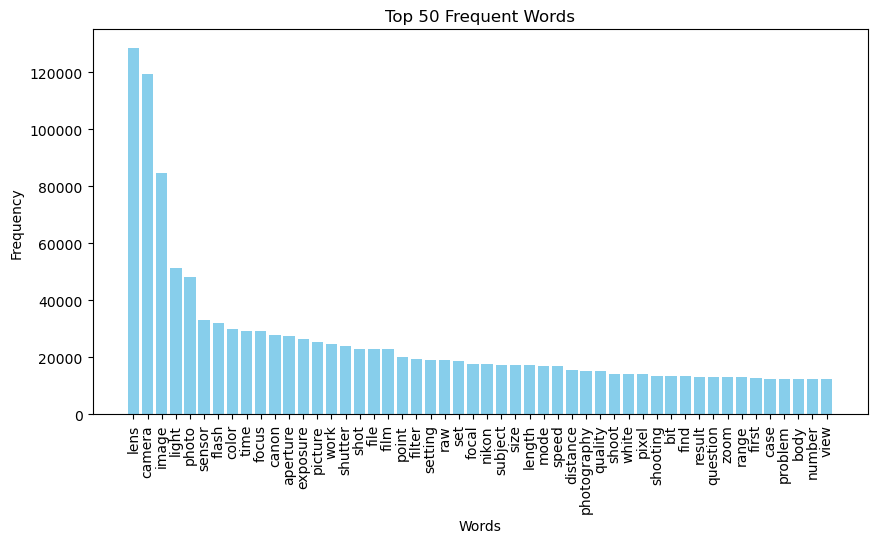

In [5]:
# Preprocess text for Title and Body fields
for post in posts_data:
    post['Preprocessed_Body'] = preprocess_text(post['Body'] or "")
    post['Preprocessed_Title'] = preprocess_text(post['Title'] or "")

# Combine all preprocessed text into a single list
all_tokens = []
for post in posts_data:
    all_tokens.extend(post['Preprocessed_Body'])
    all_tokens.extend(post['Preprocessed_Title'])

# Count word frequencies
word_counts = Counter(all_tokens)
top_50_words = word_counts.most_common(50)

# Print top 50 frequent words
print("Top 50 Frequent Words:")
for word, count in top_50_words:
    print(f"{word}: {count}")

# Visualize the top 50 words
words, counts = zip(*top_50_words)
plt.figure(figsize=(10, 5))
plt.bar(words, counts, color='skyblue')
plt.xticks(rotation=90)
plt.title("Top 50 Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()


Post Type Distribution:
Questions: 26937
Answers: 66908


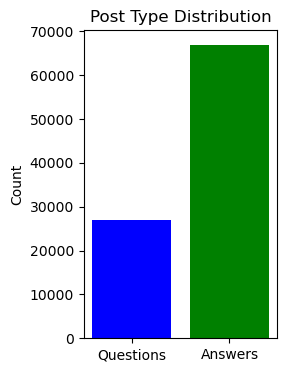


Top 10 Highest Scoring Questions:
Id: 2627, Title: Good examples of RAW's advantages over JPEG?, Score: 310
Id: 496, Title: What do all those cryptic number and letter codes in a lens name mean?, Score: 199
Id: 6471, Title: What are the best techniques for photographing overweight people?, Score: 171
Id: 6598, Title: What is the "exposure triangle"?, Score: 157
Id: 6615, Title: What is "ISO" on a digital camera?, Score: 129
Id: 2706, Title: What is bokeh, exactly?, Score: 123
Id: 3986, Title: When do the differences between APS-C and full frame sensors matter, and why?, Score: 123
Id: 450, Title: How and why do you use an image histogram?, Score: 120
Id: 164, Title: What are your easiest photography beginner tips?, Score: 117
Id: 6495, Title: In portrait photography, what is 'broad' lighting? What is 'short' lighting?, Score: 117

Top 10 Most Viewed Questions:
Id: 13717, Title: How do I convert lens focal length (mm) to x-times optical zoom?, Views: 510799
Id: 30956, Title: How can I 

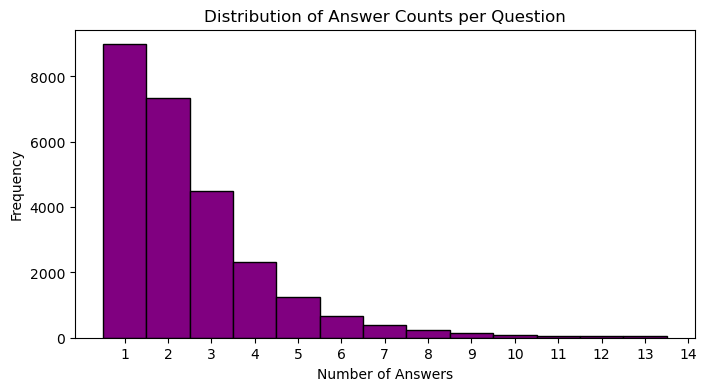


Top 10 Tags:
|lightroom|: 141
|lens|: 124
|canon|: 116
|nikon|: 75
|equipment-recommendation|: 72
|photoshop|: 66
|film|: 60
|lens|nikon|: 60
|lens|canon|: 60
|metadata|: 55


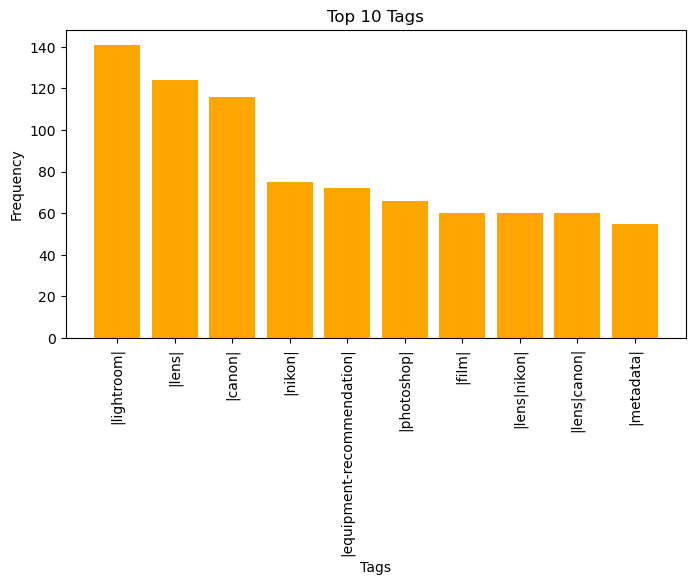

In [23]:
# Count PostTypeId occurrences
post_type_counts = defaultdict(int)
for post in posts_data:
    post_type_counts[post['PostTypeId']] += 1

# Display counts
print("Post Type Distribution:")
print(f"Questions: {post_type_counts['1']}")
print(f"Answers: {post_type_counts['2']}")

# Visualize post type distribution
labels = ['Questions', 'Answers']
counts = [post_type_counts['1'], post_type_counts['2']]
plt.figure(figsize=(2.5, 4))
plt.bar(labels, counts, color=['blue', 'green'])
plt.title("Post Type Distribution")
plt.ylabel("Count")
plt.show()

# Filter questions and sort by Score
questions = [post for post in posts_data if post['PostTypeId'] == '1' and post['Score']]
top_scoring_questions = sorted(questions, key=lambda x: int(x['Score']), reverse=True)[:10]

# Display top scoring questions
print("\nTop 10 Highest Scoring Questions:")
for question in top_scoring_questions:
    print(f"Id: {question['Id']}, Title: {question['Title']}, Score: {question['Score']}")

# Filter questions and sort by ViewCount
most_viewed_questions = sorted(questions, key=lambda x: int(x['ViewCount'] or 0), reverse=True)[:10]

# Display most viewed questions
print("\nTop 10 Most Viewed Questions:")
for question in most_viewed_questions:
    print(f"Id: {question['Id']}, Title: {question['Title']}, Views: {question['ViewCount']}")

# Percentage of questions with accepted answers
accepted_answers = [q for q in questions if q['AcceptedAnswerId']]
percentage_accepted = (len(accepted_answers) / len(questions)) * 100
print(f"\nPercentage of Questions with Accepted Answers: {percentage_accepted:.2f}%")

# Analyze answers linked to each question
answer_counts = defaultdict(int)
for post in posts_data:
    if post['PostTypeId'] == '2' and post['ParentId']:
        answer_counts[post['ParentId']] += 1

all_counts = list(answer_counts.values())
average_answers = sum(all_counts) / len(all_counts) if all_counts else 0
median_answers = np.median(all_counts) if all_counts else 0

print(f"\nAverage Number of Answers per Question: {average_answers:.2f}")
print(f"Median Number of Answers per Question: {median_answers}")

# Visualize answer counts distribution
plt.figure(figsize=(8, 4))
plt.hist(all_counts, bins=range(1, 15), color='purple', edgecolor='black', align='left')
plt.title("Distribution of Answer Counts per Question")
plt.xlabel("Number of Answers")
plt.ylabel("Frequency")
plt.xticks(range(1, 15))
plt.show()

# Analyze and count tags
tag_list = []
for post in posts_data:
    if 'Tags' in post and post['Tags']:
        tags = post['Tags'].strip('<>').split('><')
        tag_list.extend(tags)

tag_counts = Counter(tag_list)
top_10_tags = tag_counts.most_common(10)

# Display top tags
print("\nTop 10 Tags:")
for tag, count in top_10_tags:
    print(f"{tag}: {count}")

# Visualize top tags
tags, counts = zip(*top_10_tags)
plt.figure(figsize=(8, 4))
plt.bar(tags, counts, color='orange')
plt.title("Top 10 Tags")
plt.xlabel("Tags")
plt.ylabel("Frequency")
plt.xticks(rotation=90)
plt.show()



Position of Accepted Answers:
Position 1: 8536 times
Position 2: 3440 times
Position 3: 1235 times
Position 4: 424 times
Position 5: 175 times
Position 6: 72 times
Position 7: 22 times
Position 8: 10 times
Position 9: 9 times
Position 10: 4 times
Position 11: 3 times
Position 12: 1 times
Position 14: 2 times
Average Position of Accepted Answers: 1.62


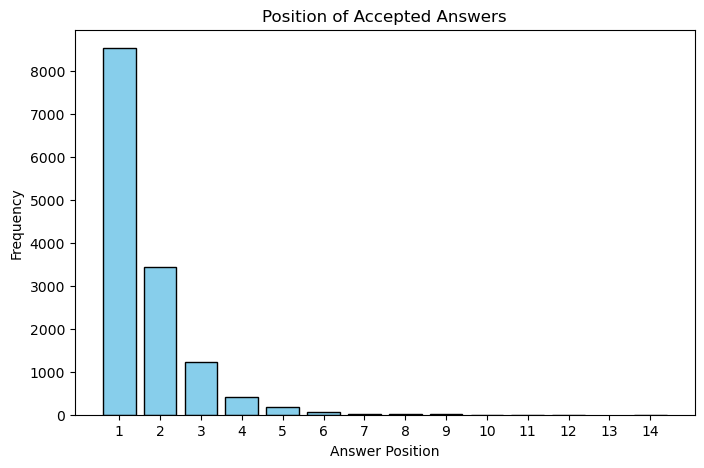

In [4]:
# Get accepted answer positions
accepted_answer_positions = []

for question in posts_data:
    if question['PostTypeId'] == "1" and question['AcceptedAnswerId']:
        # Filter answers to this question
        answers = [
            post for post in posts_data
            if post['PostTypeId'] == "2" and post['ParentId'] == question['Id']
        ]
        # Sort answers by CreationDate
        answers = sorted(answers, key=lambda x: x['CreationDate'])
        # Find the position of the accepted answer
        for i, answer in enumerate(answers):
            if answer['Id'] == question['AcceptedAnswerId']:
                accepted_answer_positions.append(i + 1)
                break

# Analyze positions
position_counts = Counter(accepted_answer_positions)
average_position = np.mean(accepted_answer_positions) if accepted_answer_positions else 0

print("\nPosition of Accepted Answers:")
for position, count in sorted(position_counts.items()):
    print(f"Position {position}: {count} times")
print(f"Average Position of Accepted Answers: {average_position:.2f}")

# Visualize positions
plt.figure(figsize=(8, 5))
plt.bar(position_counts.keys(), position_counts.values(), color='skyblue', edgecolor='black')
plt.title("Position of Accepted Answers")
plt.xlabel("Answer Position")
plt.ylabel("Frequency")
plt.xticks(range(1, max(position_counts.keys()) + 1))
plt.show()


In [12]:
# Scores of Accepted vs. Non-Accepted Answers
accepted_scores = []
non_accepted_scores = []

for question in posts_data:
    if question['PostTypeId'] == "1" and question['AcceptedAnswerId']:
        # Filter answers to this question
        answers = [
            post for post in posts_data
            if post['PostTypeId'] == "2" and post['ParentId'] == question['Id']
        ]
        for answer in answers:
            if answer['Id'] == question['AcceptedAnswerId']:
                accepted_scores.append(int(answer['Score'] or 0))
            else:
                non_accepted_scores.append(int(answer['Score'] or 0))

# Display statistics
print(f"\nAverage Score of Accepted Answers: {np.mean(accepted_scores):.2f}")
print(f"Average Score of Non-Accepted Answers: {np.mean(non_accepted_scores):.2f}")
print(f"\nMedian Score of Accepted Answers: {np.median(accepted_scores):.2f}")
print(f"Median Score of Non-Accepted Answers: {np.median(non_accepted_scores):.2f}")



Average Score of Accepted Answers: 7.10
Average Score of Non-Accepted Answers: 3.14

Median Score of Accepted Answers: 4.00
Median Score of Non-Accepted Answers: 2.00


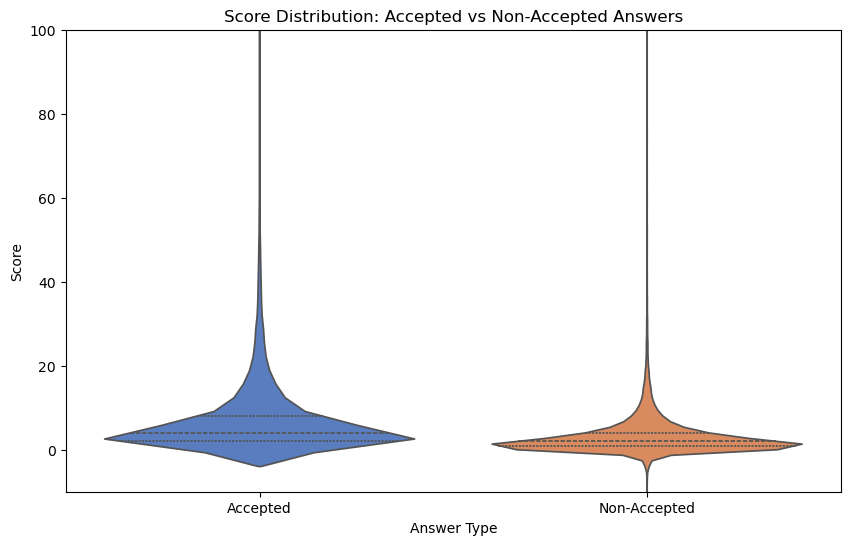

In [14]:
data = pd.DataFrame({
    'Score': accepted_scores + non_accepted_scores,
    'Type': ['Accepted'] * len(accepted_scores) + ['Non-Accepted'] * len(non_accepted_scores)
})

# Violin plot with updated syntax
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=data,
    x='Type',
    y='Score',
    hue='Type',
    inner='quartile',
    cut=0,
    palette='muted',
    dodge=False,  # Disable split/dodge since `Type` is already used for x-axis
    legend=False  # No need for a redundant legend here
)
plt.title("Score Distribution: Accepted vs Non-Accepted Answers")
plt.xlabel("Answer Type")
plt.ylabel("Score")
plt.ylim(-10, 100)  # Adjust range to exclude extreme outliers
plt.show()




Top Tags by Total Answers:
lens: 8193
canon: 5883
equipment-recommendation: 4884
nikon: 4341
lightroom: 2593
dslr: 2587
flash: 2533
exposure: 2406
film: 2396
post-processing: 2313


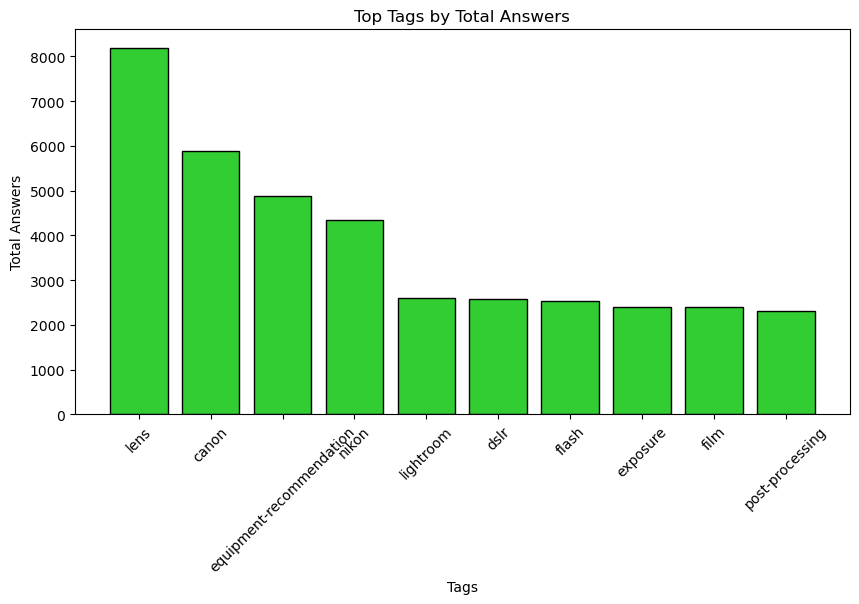

In [6]:
# Count answers per tag
tag_answer_counts = defaultdict(int)

for post in posts_data:
    if post['PostTypeId'] == "1" and post['Tags']:
        tags = post['Tags'].strip('|').split('|')
        answer_count = int(post['AnswerCount'] or 0)
        for tag in tags:
            tag_answer_counts[tag] += answer_count

# Top tags by answer count
top_tags_by_answers = sorted(tag_answer_counts.items(), key=lambda x: x[1], reverse=True)[:10]

# Display and visualize
print("\nTop Tags by Total Answers:")
for tag, count in top_tags_by_answers:
    print(f"{tag}: {count}")

tags, counts = zip(*top_tags_by_answers)
plt.figure(figsize=(10, 5))
plt.bar(tags, counts, color='limegreen', edgecolor='black')
plt.title("Top Tags by Total Answers")
plt.xlabel("Tags")
plt.ylabel("Total Answers")
plt.xticks(rotation=45)
plt.show()



Correlation Between View Count and Score: 0.36


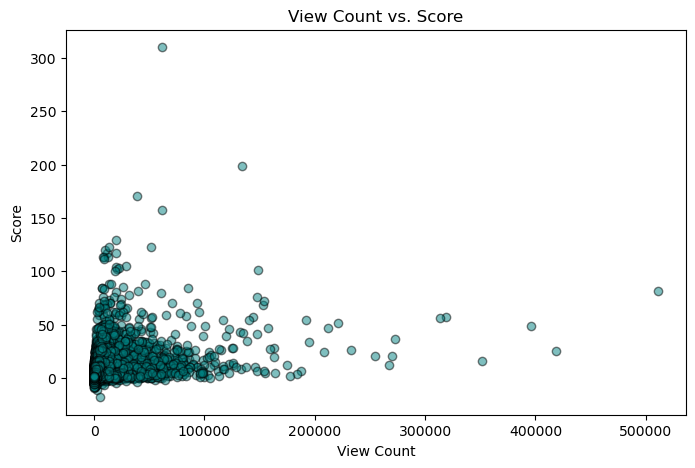

In [7]:
# Extract views and scores
view_scores = [
    (int(post['ViewCount'] or 0), int(post['Score'] or 0))
    for post in posts_data
    if post['PostTypeId'] == "1" and post['ViewCount'] and post['Score']
]

views, scores = zip(*view_scores)
correlation = np.corrcoef(views, scores)[0, 1]

print(f"\nCorrelation Between View Count and Score: {correlation:.2f}")

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(views, scores, alpha=0.5, color='teal', edgecolor='black')
plt.title("View Count vs. Score")
plt.xlabel("View Count")
plt.ylabel("Score")
plt.show()



Average Length of Questions: 112.90 words
Median Length of Questions: 89.00 words
Average Length of Answers: 183.03 words
Median Length of Answers: 128.00 words


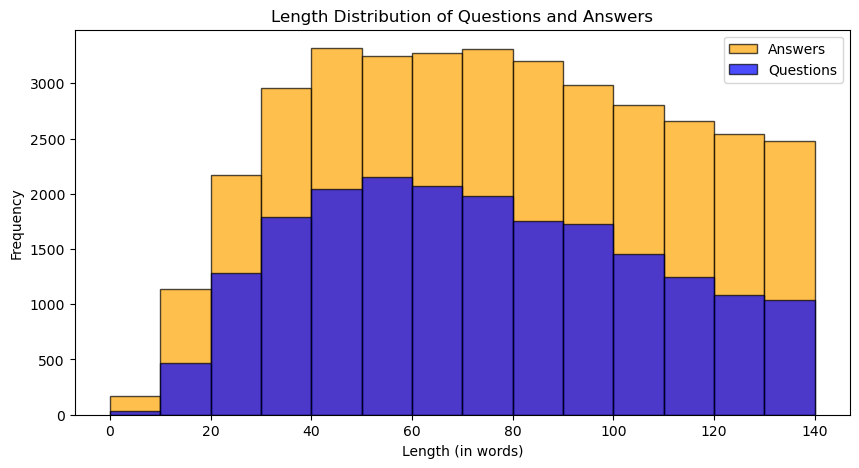

In [9]:
# Length of Questions and Answers
question_lengths = [
    len(post['Body'].split()) for post in posts_data
    if post['PostTypeId'] == "1" and post['Body']
]

answer_lengths = [
    len(post['Body'].split()) for post in posts_data
    if post['PostTypeId'] == "2" and post['Body']
]

print(f"\nAverage Length of Questions: {np.mean(question_lengths):.2f} words")
print(f"Median Length of Questions: {np.median(question_lengths):.2f} words")
print(f"Average Length of Answers: {np.mean(answer_lengths):.2f} words")
print(f"Median Length of Answers: {np.median(answer_lengths):.2f} words")

# Visualize length distributions
plt.figure(figsize=(10, 5))
plt.hist(answer_lengths, bins=range(0, 150, 10), alpha=0.7, label="Answers", color='orange', edgecolor='black')
plt.hist(question_lengths, bins=range(0, 150, 10), alpha=0.7, label="Questions", color='blue', edgecolor='black')
plt.title("Length Distribution of Questions and Answers")
plt.xlabel("Length (in words)")
plt.ylabel("Frequency")
plt.legend()
plt.show()



Total Unanswered Questions: 780
Percentage of Unanswered Questions: 2.90%

Top Tags in Unanswered Questions:
lens: 74
canon: 73
nikon: 65
lightroom: 46
film: 42
troubleshooting: 28
dslr: 27
photo-editing: 27
equipment-recommendation: 23
flash: 22


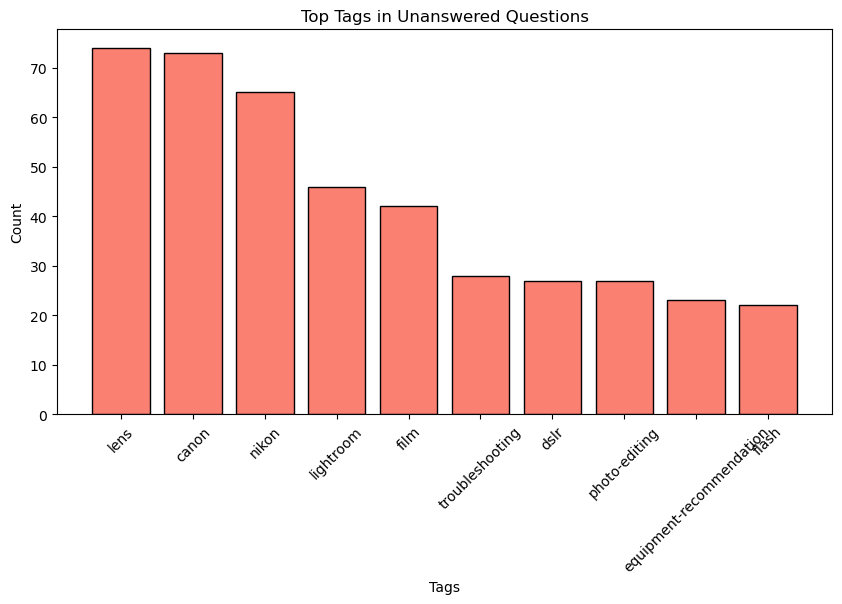

In [10]:
# Filter unanswered questions
unanswered_questions = [
    post for post in posts_data
    if post['PostTypeId'] == "1" and int(post.get('AnswerCount', 0)) == 0
]

# Display unanswered question statistics
print(f"\nTotal Unanswered Questions: {len(unanswered_questions)}")
unanswered_percentage = (len(unanswered_questions) / len([q for q in posts_data if q['PostTypeId'] == "1"])) * 100
print(f"Percentage of Unanswered Questions: {unanswered_percentage:.2f}%")

# Tags associated with unanswered questions
tag_counts_unanswered = Counter()
for question in unanswered_questions:
    if question['Tags']:
        tags = question['Tags'].strip('|').split('|')
        tag_counts_unanswered.update(tags)

# Top 10 tags in unanswered questions
top_tags_unanswered = tag_counts_unanswered.most_common(10)

print("\nTop Tags in Unanswered Questions:")
for tag, count in top_tags_unanswered:
    print(f"{tag}: {count}")

# Visualize tags in unanswered questions
tags, counts = zip(*top_tags_unanswered)
plt.figure(figsize=(10, 5))
plt.bar(tags, counts, color='salmon', edgecolor='black')
plt.title("Top Tags in Unanswered Questions")
plt.xlabel("Tags")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()



Top Tag Co-Occurrences:
('canon', 'lens'): 578
('lens', 'nikon'): 446
('equipment-recommendation', 'lens'): 396
('canon', 'equipment-recommendation'): 259
('lens', 'optics'): 209
('35mm', 'film'): 198
('photo-editing', 'photoshop'): 186
('focal-length', 'lens'): 185
('developing', 'film'): 178
('canon', 'flash'): 166


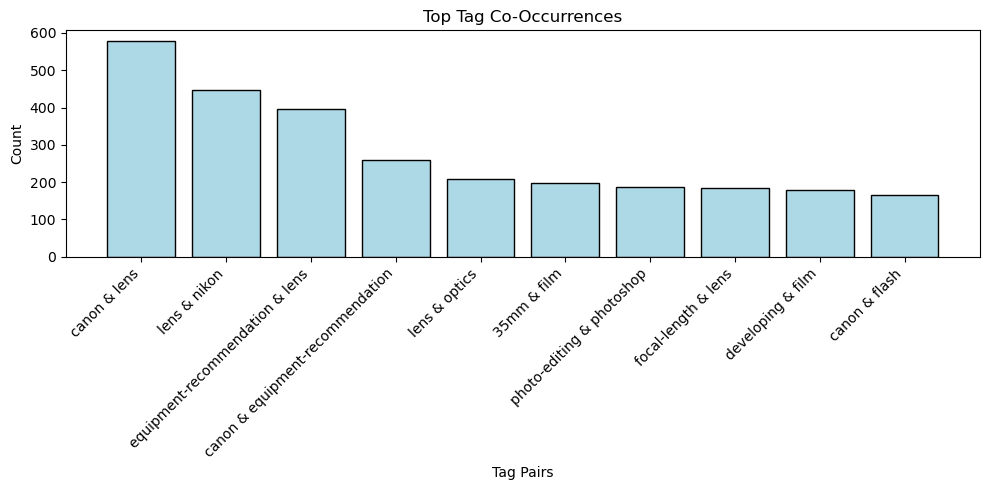

In [11]:
# Count tag co-occurrences
tag_cooccurrence = defaultdict(int)

for post in posts_data:
    if post['PostTypeId'] == "1" and post['Tags']:
        tags = post['Tags'].strip('|').split('|')
        # Generate all pairs of tags
        for tag_pair in combinations(sorted(tags), 2):
            tag_cooccurrence[tag_pair] += 1

# Sort co-occurrences by count
sorted_cooccurrences = sorted(tag_cooccurrence.items(), key=lambda x: x[1], reverse=True)[:10]

# Display and visualize top tag co-occurrences
print("\nTop Tag Co-Occurrences:")
for pair, count in sorted_cooccurrences:
    print(f"{pair}: {count}")

pairs, counts = zip(*sorted_cooccurrences)
pairs = [' & '.join(pair) for pair in pairs]

plt.figure(figsize=(10, 5))
plt.bar(pairs, counts, color='lightblue', edgecolor='black')
plt.title("Top Tag Co-Occurrences")
plt.xlabel("Tag Pairs")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [6]:
def create_corpus_and_metadata(posts_data, preprocess_func):
    """
    Create a tokenized corpus and a metadata DataFrame from posts data.

    Args:
        posts_data (list): List of parsed posts from the XML file.
        preprocess_func (function): Function to preprocess text.

    Returns:
        tuple: (corpus, metadata_df)
            - corpus: Dictionary mapping docID to tokenized content.
            - metadata_df: DataFrame containing post metadata.
    """
    corpus = {}
    metadata = []

    for post in posts_data:
        doc_id = post["Id"]

        # Preprocess title and body
        tokenized_title = preprocess_func(post["Title"] or "")
        tokenized_body = preprocess_func(post["Body"] or "")

        # Combine title and body tokens
        corpus[doc_id] = tokenized_title + tokenized_body

        # Collect metadata
        metadata.append({
            "docID": doc_id,
            "PostType": post["PostTypeId"],
            "ParentID": post["ParentId"],
            "AcceptedAnswer": bool(post.get("AcceptedAnswerId")),
            "Score": int(post["Score"] or 0),
            "ViewCount": int(post["ViewCount"] or 0),
            "Tags": post.get("Tags", "")
        })

    # Convert metadata to a DataFrame
    metadata_df = pd.DataFrame(metadata)

    return corpus, metadata_df

# Generate corpus and metadata
corpus, metadata_df = create_corpus_and_metadata(posts_data, preprocess_text)

# Save the corpus to a JSON file
with open("corpus.json", "w") as file:
    json.dump(corpus, file, indent=2)

# Save the metadata DataFrame to a CSV file
metadata_df.to_csv("metadata.csv", index=False)

print("Corpus and metadata saved to 'corpus.json' and 'metadata.csv'")


C:\Users\edgar\AppData\Local\Temp\ipykernel_22144\1375769762.py:23: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  text = BeautifulSoup(text, 'html.parser').get_text()


Corpus and metadata saved to 'corpus.json' and 'metadata.csv'


In [7]:
# Generate token-to-ID and ID-to-token mappings
def generate_token_id_mapping(corpus):
    token_to_id = {}
    id_to_token = {}
    current_id = 1

    for doc_id, tokens in corpus.items():
        for token in tokens:
            if token not in token_to_id:
                token_to_id[token] = current_id
                id_to_token[current_id] = token
                current_id += 1

    return token_to_id, id_to_token

# Load the corpus
with open("corpus.json", "r") as file:
    corpus = json.load(file)

# Create mappings
token_to_id, id_to_token = generate_token_id_mapping(corpus)

# Save mappings for later use
with open("token_to_id.json", "w") as file:
    json.dump(token_to_id, file, indent=2)
with open("id_to_token.json", "w") as file:
    json.dump(id_to_token, file, indent=2)

print("Token-to-ID mapping created!")


Token-to-ID mapping created!


In [8]:
# Generate an inverted index with token IDs
def generate_inverted_index_with_ids(corpus, token_to_id):
    inverted_index = {}

    for doc_id, tokens in corpus.items():
        for position, token in enumerate(tokens):
            token_id = token_to_id[token]
            if token_id not in inverted_index:
                inverted_index[token_id] = {}
            if doc_id not in inverted_index[token_id]:
                inverted_index[token_id][doc_id] = {"tf": 0, "positions": []}
            inverted_index[token_id][doc_id]["tf"] += 1
            inverted_index[token_id][doc_id]["positions"].append(position)

    return inverted_index

# Create the inverted index with token IDs
inverted_index_with_ids = generate_inverted_index_with_ids(corpus, token_to_id)

# Save the updated inverted index
with open("inverted_index_with_ids.json", "w") as file:
    json.dump(inverted_index_with_ids, file, indent=2)

print("Inverted index with token IDs created!")


Inverted index with token IDs created!


In [4]:
def precompute_bm25_values(inverted_index, total_docs):
    """
    Precompute document lengths, term frequencies, and average document length (avgdl) for BM25.
    
    Args:
        inverted_index (dict): Inverted index with token IDs.
        total_docs (int): Total number of documents.
    
    Returns:
        tuple: Document lengths, document frequencies, and average document length.
    """
    doc_lengths = defaultdict(int)
    doc_frequencies = defaultdict(int)

    for token_id, postings in inverted_index.items():
        doc_frequencies[token_id] = len(postings)  # Number of documents containing the token
        for doc_id, data in postings.items():
            doc_lengths[doc_id] += data['tf']  # Sum term frequencies for the document

    avgdl = sum(doc_lengths.values()) / total_docs  # Calculate average document length
    return doc_lengths, doc_frequencies, avgdl

def bm25_score(query_tokens, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs, k1=1.5, b=0.75):
    """
    Compute BM25 scores for documents based on a query.
    
    Args:
        query_tokens (list): List of token IDs from the query.
        inverted_index (dict): Inverted index with token IDs.
        doc_lengths (dict): Document lengths.
        doc_frequencies (dict): Document frequencies of terms.
        avgdl (float): Average document length.
        total_docs (int): Total number of documents.
        k1 (float): BM25 hyperparameter for term frequency saturation.
        b (float): BM25 hyperparameter for length normalization.
    
    Returns:
        list: Sorted list of (doc_id, score) tuples.
    """
    scores = defaultdict(float)

    for token_id in query_tokens:
        if str(token_id) not in inverted_index:
            continue

        postings = inverted_index[str(token_id)]
        idf = math.log((total_docs - doc_frequencies[token_id] + 0.5) / (doc_frequencies[token_id] + 0.5) + 1)

        for doc_id, data in postings.items():
            f = data['tf']  # Term frequency in the document
            d = doc_lengths[doc_id]  # Document length
            denom = f + k1 * (1 - b + b * (d / avgdl))
            scores[doc_id] += idf * (f * (k1 + 1)) / denom

    return sorted(scores.items(), key=lambda x: x[1], reverse=True)

def bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs):
    """
    Perform a BM25 search with token IDs.
    
    Args:
        query (str): User query string.
        token_to_id (dict): Mapping from tokens to token IDs.
        inverted_index (dict): Inverted index with token IDs.
        doc_lengths (dict): Document lengths.
        doc_frequencies (dict): Document frequencies.
        avgdl (float): Average document length.
        total_docs (int): Total number of documents.
    
    Returns:
        list: Sorted list of (doc_id, score) tuples.
    """
    # Preprocess the query
    query_tokens = preprocess_text(query)

    # Convert tokens to token IDs
    query_token_ids = [token_to_id[token] for token in query_tokens if token in token_to_id]

    # Calculate BM25 scores
    results = bm25_score(query_token_ids, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)
    return results

# Load the necessary files
import json

with open('corpus.json', 'r') as f:
    corpus = json.load(f)

with open('inverted_index_with_ids.json', 'r') as f:
    inverted_index = json.load(f)

with open('token_to_id.json', 'r') as f:
    token_to_id = json.load(f)

# Precompute BM25 global values
total_docs = len(corpus)  # Total number of documents
doc_lengths, doc_frequencies, avgdl = precompute_bm25_values(inverted_index, total_docs)

# Example search query
query = "best wide-angle lens for landscape photography"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")



Top Results:
DocID: 22990, Score: 72.73114701128935
DocID: 86635, Score: 71.29078742100586
DocID: 60902, Score: 68.77480630212644
DocID: 132824, Score: 68.55252253281459
DocID: 23537, Score: 68.40999227859555
DocID: 88094, Score: 65.21053495612999
DocID: 67722, Score: 64.92569959089475
DocID: 14728, Score: 62.93812181226912
DocID: 7601, Score: 62.85493782078227
DocID: 18078, Score: 62.62297484349308


In [8]:
# Example search query
query = "How to achieve depth of field effects with an APS-C camera?"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")

Top Results:
DocID: 125730, Score: 85.67831512821692
DocID: 3723, Score: 85.269806529972
DocID: 83497, Score: 74.67057162840226
DocID: 30647, Score: 72.9086085220851
DocID: 12099, Score: 70.22996297102307
DocID: 49443, Score: 69.38743033868064
DocID: 10079, Score: 69.24109901472977
DocID: 37751, Score: 69.11077142472303
DocID: 100232, Score: 65.96905792561216
DocID: 102925, Score: 65.52043411119638


In [9]:
# Example search query
query = "Best lens for astrophotography with a Nikon DSLR"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")

Top Results:
DocID: 56941, Score: 83.82249623847889
DocID: 106699, Score: 74.23206859331933
DocID: 91421, Score: 74.15932463961408
DocID: 26560, Score: 71.19621219435396
DocID: 2904, Score: 71.06096447632868
DocID: 106199, Score: 70.55282334584118
DocID: 88403, Score: 70.4923068815948
DocID: 70397, Score: 69.6381590804469
DocID: 71744, Score: 69.42757586155841
DocID: 82242, Score: 68.77480630212644


In [10]:
# Example search query
query = "Recommended ISO settings for low-light photography"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")


Top Results:
DocID: 18653, Score: 63.10427407987525
DocID: 9459, Score: 57.46143885589128
DocID: 86619, Score: 54.59929908867507
DocID: 20072, Score: 51.83650297543373
DocID: 64007, Score: 51.21361973478571
DocID: 86930, Score: 50.2066480075879
DocID: 125829, Score: 49.89794894389048
DocID: 49840, Score: 49.57974247981611
DocID: 9472, Score: 48.329291804938066
DocID: 43740, Score: 47.88865305283906


In [11]:
# Example search query
query = "What are the advantages of full-frame cameras over APS-C?"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")


Top Results:
DocID: 131145, Score: 78.47465669284601
DocID: 86894, Score: 70.60701102693994
DocID: 113114, Score: 68.37211138548102
DocID: 45412, Score: 66.3371111774614
DocID: 54415, Score: 64.72768995861406
DocID: 15366, Score: 63.48043032219011
DocID: 840, Score: 63.17092715748282
DocID: 14510, Score: 62.655877750047416
DocID: 86145, Score: 62.36708048192786
DocID: 24351, Score: 62.129230004372985


In [12]:
# Perform a search query
query = "Best budget wide-angle lenses for landscape photography"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")

Top Results:
DocID: 22990, Score: 72.73114701128935
DocID: 86635, Score: 71.29078742100586
DocID: 39922, Score: 70.70173438037001
DocID: 92568, Score: 69.53237101673506
DocID: 60902, Score: 68.77480630212644
DocID: 132824, Score: 68.55252253281459
DocID: 23537, Score: 68.40999227859555
DocID: 62073, Score: 67.68887994243244
DocID: 72994, Score: 66.9575986145917
DocID: 10400, Score: 66.74579452946166


In [13]:
# Perform a search query
query = "How to reduce chromatic aberration in long-exposure shots?"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")

Top Results:
DocID: 26145, Score: 55.0150440833697
DocID: 72569, Score: 53.86857594957574
DocID: 98717, Score: 46.58727336539113
DocID: 25909, Score: 46.56463956600443
DocID: 103289, Score: 45.594993009574324
DocID: 80031, Score: 44.854303790998394
DocID: 75652, Score: 44.578735272939525
DocID: 23957, Score: 44.564323995855375
DocID: 91581, Score: 44.38304952312547
DocID: 20921, Score: 44.197632784508336


In [14]:
# Perform a search query
query = "Difference between optical viewfinder and electronic viewfinder"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")

Top Results:
DocID: 128193, Score: 52.01858071898013
DocID: 14242, Score: 47.88168682964975
DocID: 94087, Score: 44.578735272939525
DocID: 112024, Score: 41.11400221387454
DocID: 96152, Score: 40.74783026944452
DocID: 22709, Score: 40.198177125932844
DocID: 80586, Score: 39.537433908628714
DocID: 8165, Score: 38.84033937272928
DocID: 7024, Score: 37.783600381938754
DocID: 26219, Score: 37.44819453607886


In [15]:
# Perform a search query
query = "Canon 5D Mark IV vs Nikon D850 for portrait photography"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)

# Display top results
print("Top Results:")
for doc_id, score in results[:10]:
    print(f"DocID: {doc_id}, Score: {score}")

Top Results:
DocID: 92912, Score: 84.26724353998631
DocID: 86586, Score: 70.0149779961583
DocID: 85041, Score: 68.20709328345544
DocID: 95565, Score: 63.01756558244995
DocID: 53998, Score: 62.448226792455124
DocID: 67943, Score: 62.2119084599269
DocID: 5769, Score: 62.12457742630654
DocID: 54580, Score: 61.80469462062386
DocID: 97469, Score: 61.16687000727987
DocID: 85304, Score: 59.9353676007388


In [33]:
def refine_bm25_results(results, metadata_path, top_n=10):
    """
    Refine BM25 results by combining questions with their best answers.

    Args:
        results (list): List of (docID, score) tuples from BM25 search.
        metadata_path (str): Path to the metadata CSV file.
        top_n (int): Number of top results to return.

    Returns:
        list: Refined list of question-answer thread results.
    """
    # Load metadata
    metadata = pd.read_csv(metadata_path)

    # Prepare a dictionary to store question threads
    thread_scores = []

    alpha = 1 # weight for posts scores

    for doc_id, bm25_score in results[:top_n]:
        # Convert doc_id to string to match metadata
        doc_id = int(doc_id)

        # Retrieve metadata for the current post
        post_data = metadata[metadata['docID'] == doc_id]

        post_data = post_data.iloc[0]  # Access the first (and only) row

        # If it's a question, find the best answer
        if post_data['PostType'] == 1:  # Question
            question_score = post_data['Score']

            # Find the best answer (accepted or highest-scoring)
            answers = metadata[metadata['ParentID'] == doc_id].reset_index()  # Find answers linked to this question
            if answers.empty:
                continue            
            else:
                best_answer = answers.iloc[answers['Score'].idxmax()]
                best_answer_score = best_answer['Score']
                best_answer_id = best_answer['docID']

            thread_score = (
                bm25_score
                + alpha * math.copysign(math.log(1 + abs(question_score)), question_score)
                + alpha * math.copysign(math.log(1 + abs(best_answer_score)), best_answer_score)
            )
            
            thread_scores.append({
                'thread_score': thread_score,
                'question_id': doc_id,
                'answer_id': best_answer_id,
                'bm25_score': bm25_score,
                'question_score': question_score,
                'answer_score': best_answer_score
            })
        # If it's an answer, find the corresponding question
        elif post_data['PostType'] == 2: # Answer
            answer_score = post_data['Score']

            # Find corresponding question
            question = metadata[metadata['docID'] == post_data['ParentID']]
            question = question.iloc[0]
            question_score = question['Score']
            question_id = question['docID']

            thread_score = (
                bm25_score
                + alpha * math.copysign(math.log(1 + abs(question_score)), question_score)
                + alpha * math.copysign(math.log(1 + abs(answer_score)), answer_score)
            )

            thread_scores.append({
                'thread_score': thread_score,
                'question_id': question_id,
                'answer_id': doc_id,
                'bm25_score': bm25_score,
                'question_score': question_score,
                'answer_score': answer_score
            })

    # Remove duplicates by focusing on unique questions
    unique_threads = {}
    for thread in thread_scores:
        question_id = thread['question_id']
        if question_id not in unique_threads or thread['thread_score'] > unique_threads[question_id]['thread_score']:
            unique_threads[question_id] = thread  # Keep the thread with the highest score for the question

    # Rerank threads by combined scores
    ranked_threads = sorted(unique_threads.values(), key=lambda x: x['thread_score'], reverse=True)

    return ranked_threads[:top_n]


In [32]:
# Usage example
query = "Recommended ISO settings for low-light photography"
results = bm25_search(query, token_to_id, inverted_index, doc_lengths, doc_frequencies, avgdl, total_docs)
refined_results = refine_bm25_results(results, "metadata.csv")

# Display refined results
print("Refined Results:")
for thread in refined_results:
    print(f"Thread Score: {thread['thread_score']}, Question: {thread['question_id']}, Answer: {thread['answer_id']}, BM25 Score: {thread['bm25_score']}, Question Score: {thread['question_score']}, Answer Score: {thread['answer_score']}")
ids,score = zip(*results)


Refined Results:
Thread Score: 73.59929908867507, Question: 86619, Answer: 86626, BM25 Score: 54.59929908867507, Question Score: 8, Answer Score: 11
Thread Score: 68.10427407987525, Question: 18653, Answer: 18656, BM25 Score: 63.10427407987525, Question Score: 0, Answer Score: 5
Thread Score: 67.32929180493807, Question: 9472, Answer: 9473, BM25 Score: 48.329291804938066, Question Score: 10, Answer Score: 9
Thread Score: 64.46143885589129, Question: 9459, Answer: 9470, BM25 Score: 57.46143885589128, Question Score: 4, Answer Score: 3
Thread Score: 59.83650297543373, Question: 20072, Answer: 20073, BM25 Score: 51.83650297543373, Question Score: 5, Answer Score: 3
Thread Score: 54.57974247981611, Question: 49840, Answer: 49853, BM25 Score: 49.57974247981611, Question Score: 2, Answer Score: 3
Thread Score: 53.21361973478571, Question: 64007, Answer: 64825, BM25 Score: 51.21361973478571, Question Score: 0, Answer Score: 2
Thread Score: 53.2066480075879, Question: 86930, Answer: 86956, BM2